# What drives the price of a car?


**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing. Your goal is to understand what factors make a car more or less expensive. As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.


In [111]:
# import libraries
import json
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from itertools import permutations, combinations, combinations_with_replacement
from sklearn.base import clone
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    KFold,
    cross_val_score,
    cross_validate,
)
from sklearn.linear_model import Lasso, LinearRegression, Ridge, ElasticNet
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

In [112]:
df = pd.read_csv("data/vehicles.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  object 
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  object 
 5   model         421603 non-null  object 
 6   condition     252776 non-null  object 
 7   cylinders     249202 non-null  object 
 8   fuel          423867 non-null  object 
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  object 
 11  transmission  424324 non-null  object 
 12  VIN           265838 non-null  object 
 13  drive         296313 non-null  object 
 14  size          120519 non-null  object 
 15  type          334022 non-null  object 
 16  paint_color   296677 non-null  object 
 17  state         426880 non-null  object 
dtypes: f

In [113]:
df = df.map(lambda x: x.lower() if isinstance(x, str) else x)
df = df.map(lambda x: x.strip() if isinstance(x, str) else x)
df = df.drop(columns=["id", "region", "state"], axis=1, errors="ignore")
df["log_price"] = np.log(df["price"])
df["cbrt_odometer"] = np.cbrt(df["odometer"])
df["age"] = np.where(df["year"].notna(), 2022 - df["year"], np.nan)
with open("manufacturer_to_region.json") as f:
    brand_origin_map = json.load(f)
df["brand_origin"] = df["manufacturer"].astype(str).map(brand_origin_map)
with open("manufacturer_to_luxury.json") as f:
    brand_status_map = json.load(f)
df["brand_status"] = df["manufacturer"].astype(str).map(brand_status_map)

/Users/amandeep/Documents/my_projects/used_car_price_prediction/.venv/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [114]:
df.describe()

/Users/amandeep/Documents/my_projects/used_car_price_prediction/.venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,price,year,odometer,log_price,cbrt_odometer,age
count,4.268800e+05,425675.000000,4.224800e+05,4.268800e+05,422480.000000,425675.000000
mean,7.519903e+04,2011.235191,9.804333e+04,-inf,41.868481,10.764809
std,1.218228e+07,9.452120,2.138815e+05,NaN,13.725835,9.452120
min,0.000000e+00,1900.000000,0.000000e+00,-inf,0.000000,0.000000
25%,5.900000e+03,2008.000000,3.770400e+04,8.682708e+00,33.532233,5.000000
50%,1.395000e+04,2013.000000,8.554800e+04,9.543235e+00,44.062583,9.000000
75%,2.648575e+04,2017.000000,1.335425e+05,1.018436e+01,51.113996,14.000000
max,3.736929e+09,2022.000000,1.000000e+07,2.204153e+01,215.443469,122.000000


# Outlire Analysis


## Price


In [115]:
df[["price", "log_price"]].describe().T

/Users/amandeep/Documents/my_projects/used_car_price_prediction/.venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
price,426880.0,7.519903e+04,1.218228e+07,0.0,5900.000000,13950.000000,26485.750000,3.736929e+09
log_price,426880.0,-inf,NaN,-inf,8.682708,9.543235,10.184362,2.204153e+01


In [116]:
df = df.loc[df["price"] > 315]
iqr = df["log_price"].quantile(0.75) - df["log_price"].quantile(0.25)
upper_limit = df["log_price"].quantile(0.75) + 1.5 * iqr
print("upper limit of log(price): ", upper_limit)
print("e^upper_limit: ", np.e**upper_limit)
print(
    "No of observation with log(price) > upper limit: ",
    df.loc[df["log_price"] > upper_limit, "price"].count(),
)

upper limit of log(price):  12.215019006987147
e^upper_limit:  201797.29995131723
No of observation with log(price) > upper limit:  124


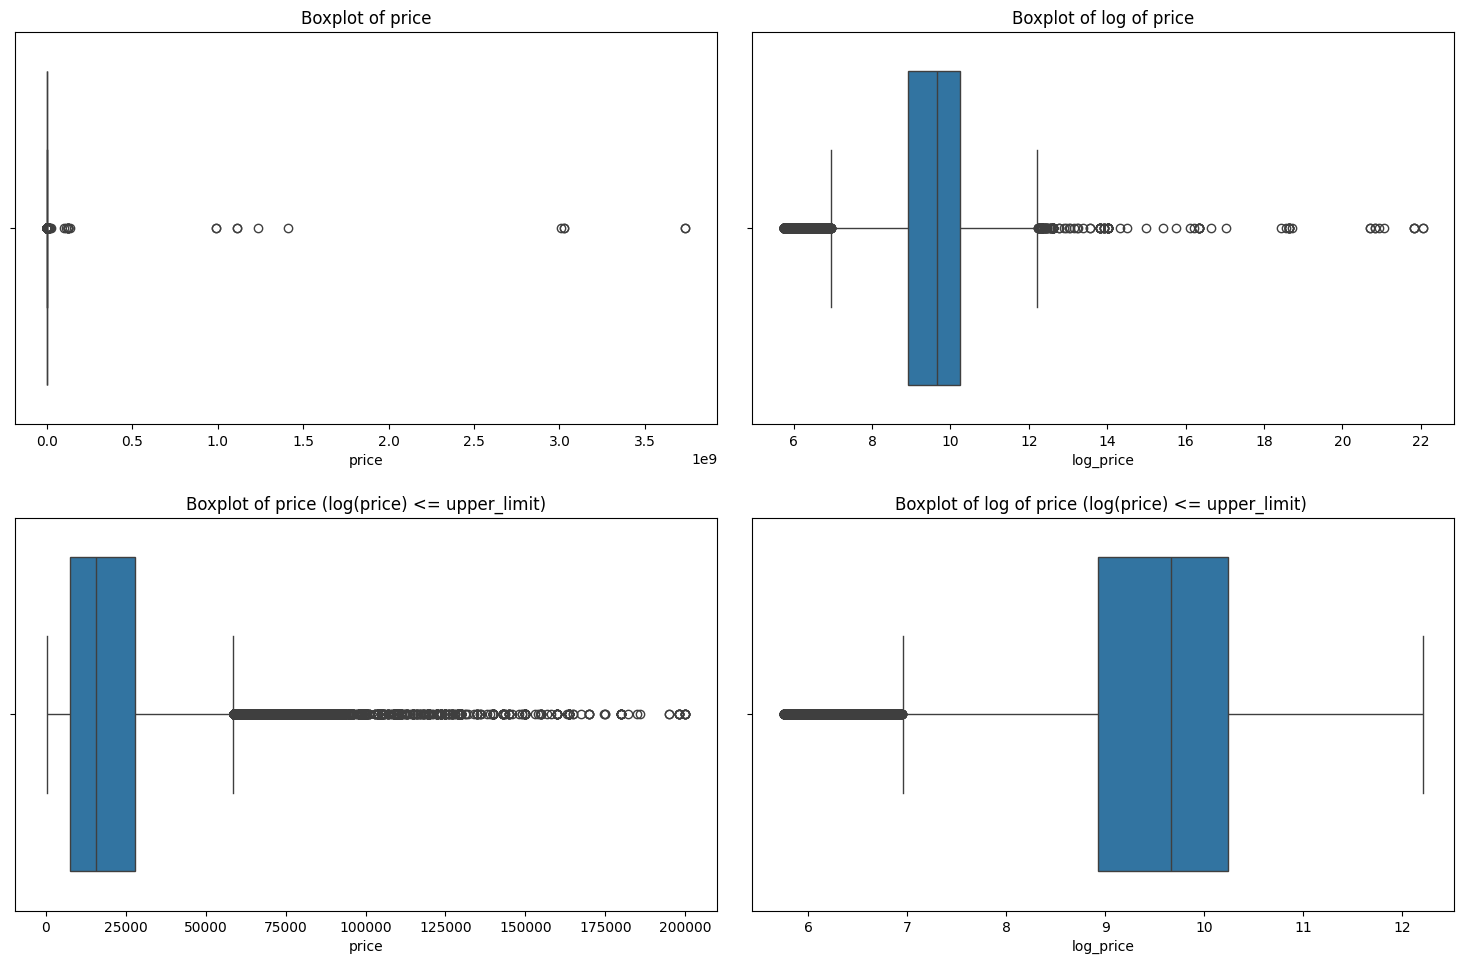

In [117]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.boxplot(data=df, x="price", ax=axes[0, 0])
axes[0, 0].set_title("Boxplot of price")
sns.boxplot(data=df, x="log_price", ax=axes[0, 1])
axes[0, 1].set_title("Boxplot of log of price")
# after removing log_price < upper_limit
sns.boxplot(data=df.loc[df["log_price"] <= upper_limit], x="price", ax=axes[1, 0])
axes[1, 0].set_title("Boxplot of price (log(price) <= upper_limit)")
sns.boxplot(data=df.loc[df["log_price"] <= upper_limit], x="log_price", ax=axes[1, 1])
axes[1, 1].set_title("Boxplot of log of price (log(price) <= upper_limit) ")
plt.savefig("plots/boxplot_price.png")
plt.tight_layout(pad=2.0)
plt.show()

In [118]:
df = df.loc[df["log_price"] <= upper_limit]
df_info = df[["price", "log_price"]].describe().T
df_info["skew"] = [df["price"].skew(), df["log_price"].skew()]
df_info["kurtosis"] = [df["price"].kurtosis(), df["log_price"].kurtosis()]
df_info

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
price,387066.0,19195.443694,15017.261962,316.000000,7500.000000,15775.000000,27990.000000,200000.000000,1.674228,6.300615
log_price,387066.0,9.511622,0.943776,5.755742,8.922658,9.666182,10.239603,12.206073,-0.890519,1.136392


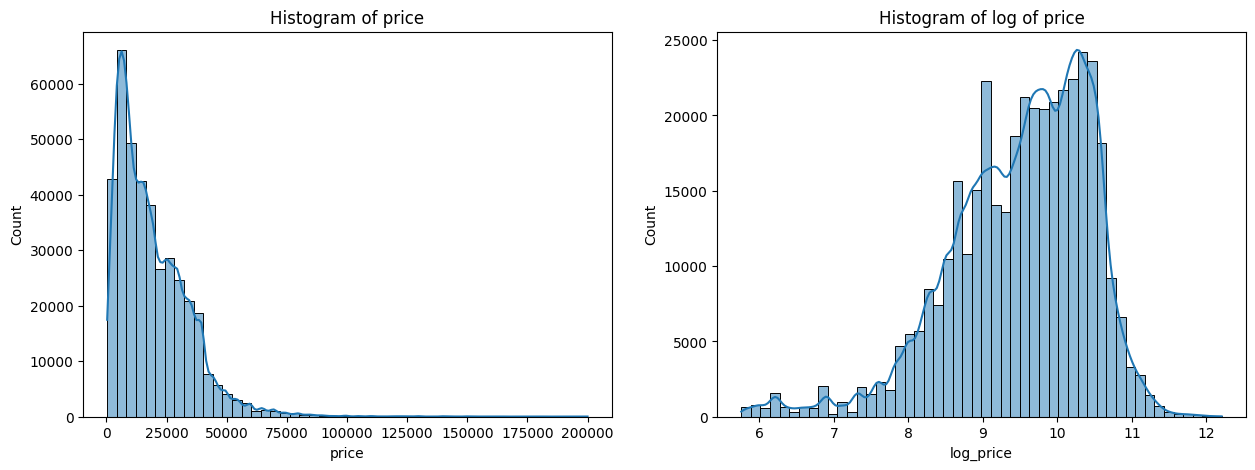

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(data=df, x="price", bins=50, ax=axes[0], kde=True)
axes[0].set_title("Histogram of price")
sns.histplot(data=df, x="log_price", bins=50, ax=axes[1], kde=True)
axes[1].set_title("Histogram of log of price")
plt.savefig("plots/histogram_price.jpeg")
plt.show()

## Odometer


In [120]:
df[["odometer", "cbrt_odometer"]].describe().T

,count,mean,std,min,25%,50%,75%,max
odometer,384882.0,98523.297842,197423.792952,0.0,38000.000000,87250.000000,135926.750000,1.000000e+07
cbrt_odometer,384882.0,42.119411,13.516254,0.0,33.619754,44.352879,51.416397,2.154435e+02


In [121]:
iqr = df["cbrt_odometer"].quantile(0.75) - df["cbrt_odometer"].quantile(0.25)
odometer_upper_limit = df["cbrt_odometer"].quantile(0.75) + 1.5 * iqr
print("upper limit of cuberoot(odometer): ", odometer_upper_limit)
print("e^odometer_upper_limit: ", odometer_upper_limit**3)
print(
    "No of observation with cuberoot(odometer) > upper limit: ",
    df.loc[df["cbrt_odometer"] > odometer_upper_limit, "odometer"].size,
)

upper limit of cuberoot(odometer):  78.11136262180261
e^odometer_upper_limit:  476587.49393646687
No of observation with cuberoot(odometer) > upper limit:  1226


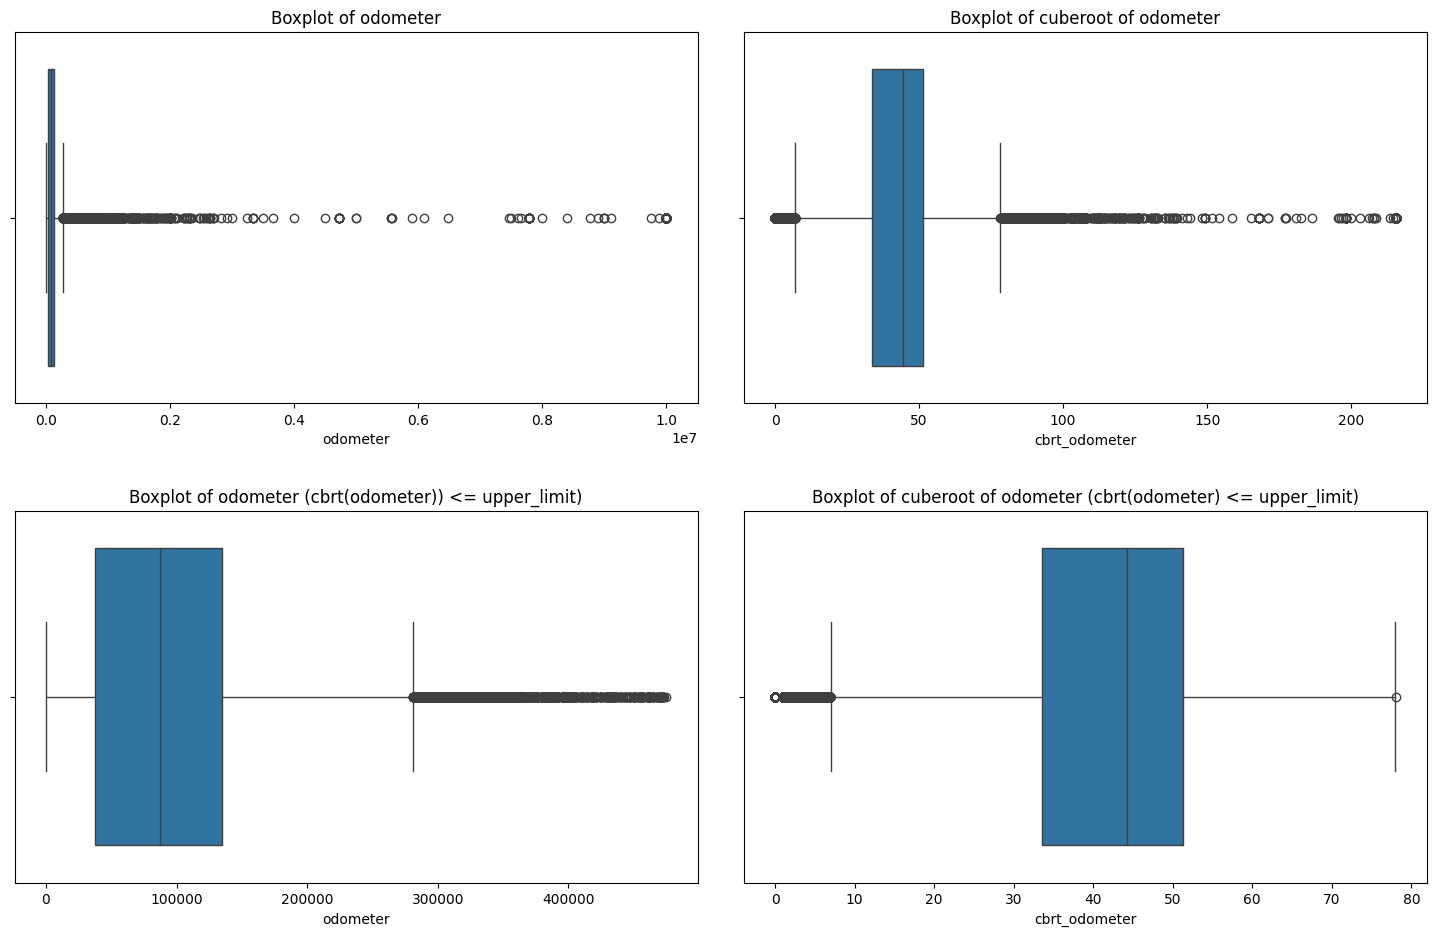

In [122]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.boxplot(data=df, x="odometer", ax=axes[0, 0])
axes[0, 0].set_title("Boxplot of odometer")
sns.boxplot(data=df, x="cbrt_odometer", ax=axes[0, 1])
axes[0, 1].set_title("Boxplot of cuberoot of odometer")
# after removing cbrt_odometer < upper_limit
sns.boxplot(
    data=df.loc[df["cbrt_odometer"] <= odometer_upper_limit],
    x="odometer",
    ax=axes[1, 0],
)
axes[1, 0].set_title("Boxplot of odometer (cbrt(odometer)) <= upper_limit)")
sns.boxplot(
    data=df.loc[df["cbrt_odometer"] <= odometer_upper_limit],
    x="cbrt_odometer",
    ax=axes[1, 1],
)
axes[1, 1].set_title("Boxplot of cuberoot of odometer (cbrt(odometer) <= upper_limit)")
plt.savefig("plots/boxplot_odometer.png")
plt.tight_layout(pad=3.0)
plt.show()

In [123]:
df = df.loc[df["cbrt_odometer"] <= odometer_upper_limit]
df_info = df[["odometer", "cbrt_odometer"]].describe().T
df_info["skew"] = [df["odometer"].skew(), df["cbrt_odometer"].skew()]
df_info["kurtosis"] = [df["odometer"].kurtosis(), df["cbrt_odometer"].kurtosis()]
df_info

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
odometer,383656.0,92554.156930,64051.866483,0.0,37867.000000,87000.000000,135150.000000,475000.000000,0.717308,0.601680
cbrt_odometer,383656.0,41.898933,12.781209,0.0,33.580485,44.310476,51.318271,78.024538,-0.734692,0.433097


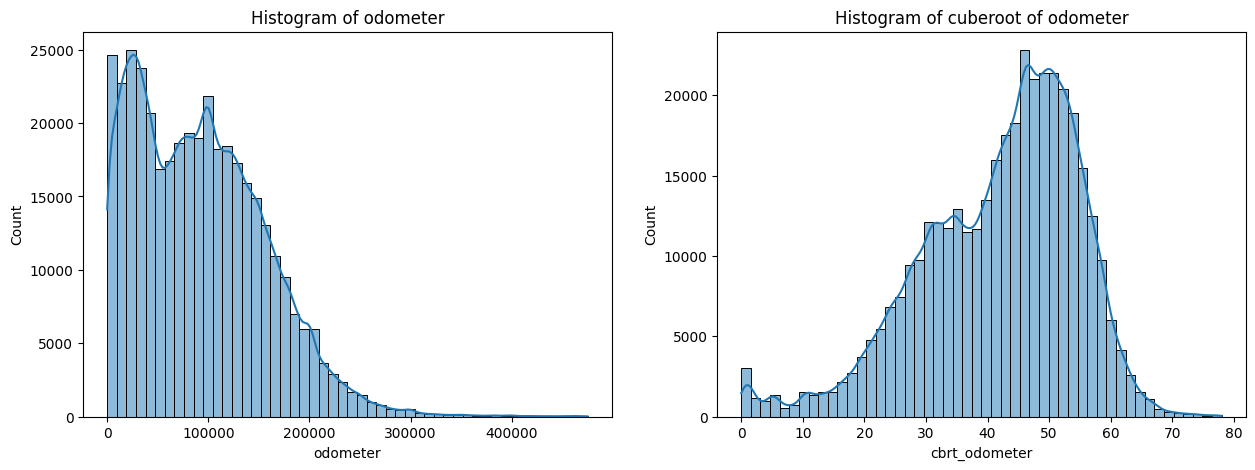

In [124]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(data=df, x="odometer", bins=50, ax=axes[0], kde=True)
axes[0].set_title("Histogram of odometer")
sns.histplot(data=df, x="cbrt_odometer", bins=50, ax=axes[1], kde=True)
axes[1].set_title("Histogram of cuberoot of odometer")
plt.savefig("plots/histogram_odometer.jpeg")
plt.show()

# Missing Value Analysis

We will analyse all the 17 features for data types, missing values, irregularities, etc and plan necessary data transformations to arrive at quality data for analysis. We will also create new features if needed.


In [125]:
df_info = pd.DataFrame(
    {
        "columns": df.columns,
        "non_null_count": df.notna().sum().values,
        "null_count": df.isna().sum().values,
        "data_type": df.dtypes.values,
    }
)
df_info["percentage_missing"] = round((df_info["null_count"] / df.index.size * 100), 2)
df_info

,columns,non_null_count,null_count,data_type,percentage_missing
0,price,383656,0,int64,0.00
1,year,382547,1109,float64,0.29
2,manufacturer,368565,15091,object,3.93
3,model,379251,4405,object,1.15
4,condition,237647,146009,object,38.06
5,cylinders,227680,155976,object,40.66
6,fuel,381336,2320,object,0.60
7,odometer,383656,0,float64,0.00
8,title_status,376559,7097,object,1.85
9,transmission,382141,1515,object,0.39


In [126]:
# Data Triangulation

## mark others to nan as it is more close to not being known
df.loc[(df["cylinders"] == "other"), "cylinders"] = (
    np.nan
)  ## for gas/diesel powered cars, cylinder count cannot be others
df.loc[df["fuel"] == "other", "fuel"] = np.nan  ## fuel can be gas, diesel or electric
df.loc[(df["transmission"] == "other"), "transmission"] = (
    np.nan
)  ## transmission can be manual or automatic. Other means its not known

## General data triangulation
df.loc[df["fuel"].isin(["electric"]), "transmission"] = "automatic"
df.loc[df["type"].isin(["bus"]), "size"] = "full-size"
df.loc[(df["type"].isin(["mini-van"])) & (df["size"] != "full-size"), "size"] = (
    "mid-size"
)
df.loc[df["manufacturer"].isin(["land rover", "rover"]), "manufacturer"] = "land rover"
df.loc[df["size"].isin(["full-size", "full_size"]), "size"] = "full-size"


# Filling and harmonising values for model = f-150
df.loc[df["model"] == "f-150", "type"] = "pickup"
df.loc[df["model"] == "f-150", "size"] = "full-size"
df.loc[(df["model"] == "f-150") & (df["drive"] == "fwd"), "drive"] = "4wd"
df.loc[
    (df["model"] == "f-150")
    & (df["cylinders"].isin(["10 cylinders", "4 cylinders", "other", "3 cylinders"])),
    "cylinders",
] = np.nan

# filling and hanrmonsing values for mode containing silverado
df.loc[df["model"] == "silverado", "type"] = "pickup"
df.loc[(df["model"].str.contains("silverado", na=False)), "size"] = "full-size"
df.loc[
    (df["model"].str.contains("silverado", na=False))
    & (df["cylinders"].isin(["10 cylinders", "other", "5 cylinders", "12 cylinders"])),
    "cylinders",
] = np.nan

# filling and harmonising values for model containing 1500
df.loc[df["model"] == "1500", "type"] = "pickup"
df.loc[(df["model"].str.contains("1500", na=False)), "size"] = "full-size"
df.loc[
    (df["model"].str.contains("1500", na=False))
    & (df["cylinders"].isin(["10 cylinders", "other", "5 cylinders"])),
    "cylinders",
] = np.nan

# filling and harmonising values for model containing wrangler
df.loc[(df["model"].str.contains("wrangler", na=False)), "drive"] = "4wd"
df.loc[(df["model"].str.contains("wrangler", na=False)), "type"] = "suv"
df.loc[
    (df["model"].isin(["wrangler"])) & (df["cylinders"] == "6 cylinders"), "size"
] = "mid-size"
df.loc[
    (df["model"].isin(["wrangler"])) & (df["cylinders"] == "4 cylinders"), "size"
] = "compact"
df.loc[
    (df["model"].str.contains("wrangler", na=False))
    & (df["cylinders"].isin(["8 cylinders", "other", "5 cylinders"])),
    "cylinders",
] = np.nan

# filling and harmonising values for model containing camry
df.loc[(df["model"].str.contains("camry", na=False)), "manufacturer"] = "toyota"
df.loc[(df["model"].str.contains("camry", na=False)), "type"] = "sedan"
df.loc[(df["model"].str.contains("camry", na=False)), "size"] = "mid-size"
df.loc[(df["model"].str.contains("camry", na=False)), "cylinders"] = "4 cylinders"
df.loc[(df["model"].str.contains("camry", na=False)), "drive"] = "fwd"

## Filling null values for model conaining: scion
df.loc[(df["model"].str.contains("scion", na=False)), "manufacturer"] = "toyota"
df.loc[(df["model"].str.contains("scion", na=False)), "cylinders"] = "4 cylinders"
df.loc[(df["model"].str.contains("scion", na=False)), "fuel"] = "gas"

## Filling null values for model containing: genesis g80
df.loc[(df["model"].str.contains("genesis", na=False)), "manufacturer"] = (
    "genesis motors"
)
df.loc[(df["model"].str.contains("genesis g80", na=False)), "cylinders"] = "6 cylinders"
df.loc[(df["model"].str.contains("genesis g80", na=False)), "transmission"] = (
    "automatic"
)
df.loc[(df["model"].str.contains("genesis g80", na=False)), "drive"] = "rwd"
df.loc[(df["model"].str.contains("genesis g80", na=False)), "size"] = "mid-size"

## Filling null values for model containing: genesis g70
df.loc[(df["model"].str.contains("genesis g70", na=False)), "cylinders"] = "4 cylinders"

## Filling null values for model containing : hummer h2, hummer h3
df.loc[(df["model"].str.contains("hummer", na=False)), "manufacturer"] = "gmc"
df.loc[(df["model"].str.contains("hummer", na=False)), "type"] = "suv"
df.loc[(df["model"].str.contains("hummer", na=False)), "size"] = "full-size"
df.loc[(df["model"].str.contains("hummer", na=False)), "cylinders"] = "8 cylinders"
df.loc[(df["model"].str.contains("hummer", na=False)), "drive"] = "4wd"
df.loc[(df["model"].str.contains("hummer h2", na=False)), "fuel"] = "gas"
df.loc[(df["model"].str.contains("hummer h3", na=False)), "fuel"] = "gas"

## Filling null values for model containing: smart fortwo passion hatchback
df.loc[
    (df["model"].str.contains("smart fortwo passion hatchback", na=False)),
    "manufacturer",
] = "smart"
df.loc[
    (df["model"].str.contains("smart fortwo passion hatchback", na=False)), "cylinders"
] = "3 cylinders"
df.loc[
    (df["model"].str.contains("smart fortwo passion hatchback", na=False)), "size"
] = "ultra-compact"

In [127]:
df_info["new_null_count"] = df.isna().sum().values
df_info["new_percentage_missing"] = round(
    (df_info["new_null_count"] / df.index.size) * 100, 2
)
df_info["percent_change"] = (
    (df_info["null_count"] - df_info["new_null_count"])
    .div(df_info["null_count"])
    .fillna(0)
) * 100
df_info.loc[df_info["percent_change"] != 0, ["columns", "percent_change"]]

,columns,percent_change
2,manufacturer,21.184812
5,cylinders,1.725907
6,fuel,-1177.456897
9,transmission,-3945.478548
11,drive,1.834886
12,size,12.257340
13,type,6.924513


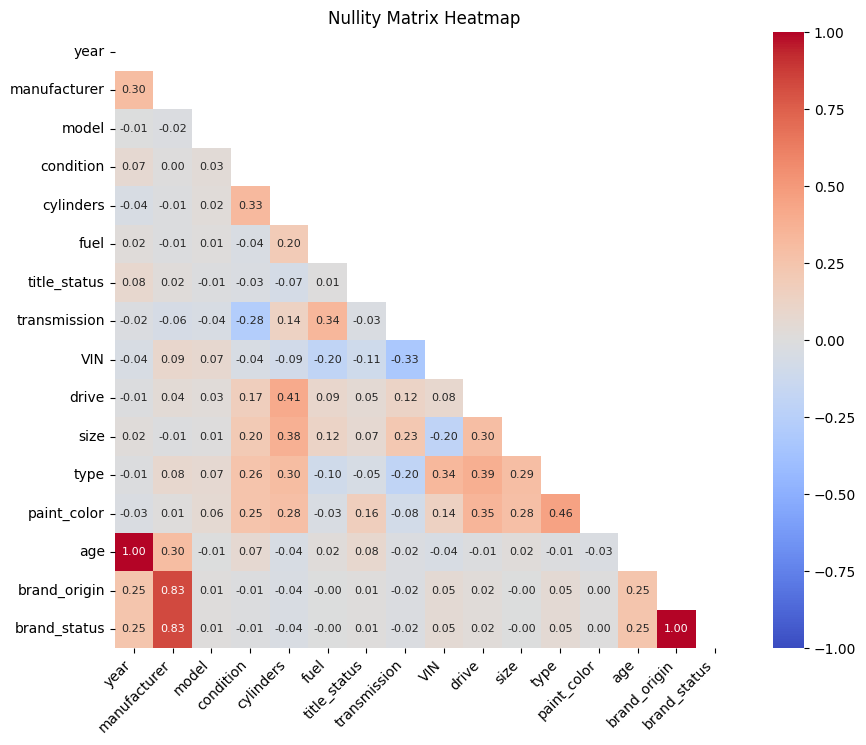

In [128]:
# Nullity correlation analysis & Nullity corr matrix heatmap
null_df = df.isna().drop(columns=["price", "log_price", "cbrt_odometer", "odometer"])
nullity_corr = null_df.corr(method="pearson").dropna()
plt.figure(figsize=(10, 8))
sns.heatmap(
    data=nullity_corr,
    mask=np.triu(nullity_corr),
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    vmax=1,
    vmin=-1,
    cmap="coolwarm",
)
plt.title("Nullity Matrix Heatmap")
plt.xticks(rotation=45, ha="right")
plt.savefig("plots/nullity_matrix.jpeg")
plt.show()

In [129]:
nc_stack = (
    nullity_corr.stack()
    .reset_index(name="correlation")
    .rename(columns={"level_0": "feature_1"})
)
nc_stack = nc_stack.loc[
    (nc_stack["correlation"] != 1) & (nc_stack["correlation"] != -1)
]
nc_stack.loc[
    (nc_stack["correlation"] > 0.39) | (nc_stack["correlation"] < -0.39)
].count() / 2

feature_1      4.0
level_1        4.0
correlation    4.0
dtype: float64

# Exploratory Analysis


In [130]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,383656.0,19204.420220,14996.964807,316.000000,7500.000000,15800.000000,27990.000000,200000.000000
year,382547.0,2011.039786,9.503806,1900.000000,2008.000000,2013.000000,2017.000000,2022.000000
odometer,383656.0,92554.156930,64051.866483,0.000000,37867.000000,87000.000000,135150.000000,475000.000000
log_price,383656.0,9.513076,0.942114,5.755742,8.922658,9.667765,10.239603,12.206073
cbrt_odometer,383656.0,41.898933,12.781209,0.000000,33.580485,44.310476,51.318271,78.024538
age,382547.0,10.960214,9.503806,0.000000,5.000000,9.000000,14.000000,122.000000


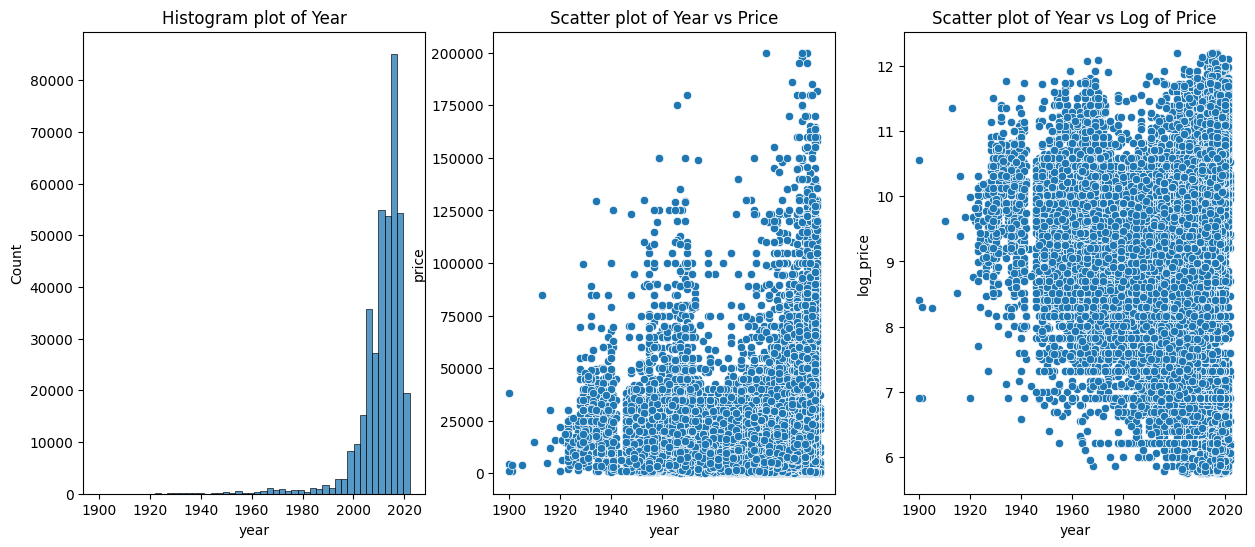

In [131]:
## Year, Year vs Price, Year vs Log
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
sns.histplot(data=df, x="year", bins=50, ax=axes[0])
axes[0].set_title("Histogram plot of Year")
sns.scatterplot(data=df, x="year", y="price", ax=axes[1])
axes[1].set_title("Scatter plot of Year vs Price")
sns.scatterplot(data=df, x="year", y="log_price", ax=axes[2])
axes[2].set_title("Scatter plot of Year vs Log of Price")
plt.savefig("plots/plots_year.jpeg")
plt.show()

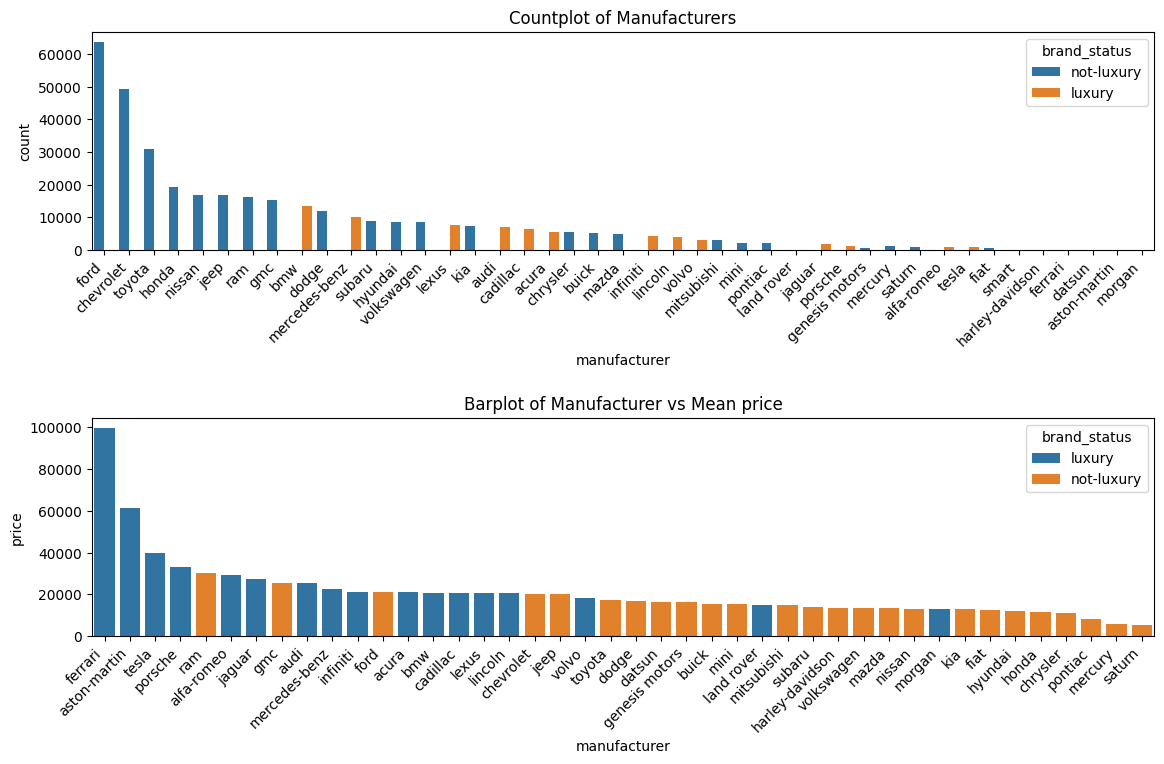

In [132]:
# Manufacturer, Manufacturer vs Price
manufacturer_df = (
    df.groupby(by=["manufacturer", "brand_status"])
    .agg({"price": "mean", "log_price": "mean"})
    .reset_index()
)
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
sns.countplot(
    data=df,
    x="manufacturer",
    order=df["manufacturer"].value_counts().index,
    ax=axes[0],
    hue="brand_status",
)
axes[0].set_title("Countplot of Manufacturers")
sns.barplot(
    data=manufacturer_df,
    x="manufacturer",
    y="price",
    ax=axes[1],
    hue="brand_status",
    order=manufacturer_df.sort_values(by="price", ascending=False)["manufacturer"],
)
axes[1].set_title("Barplot of Manufacturer vs Mean price")
for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(pad=2.0)
plt.savefig("plots/plots_manufacturer.jpeg")
plt.show()

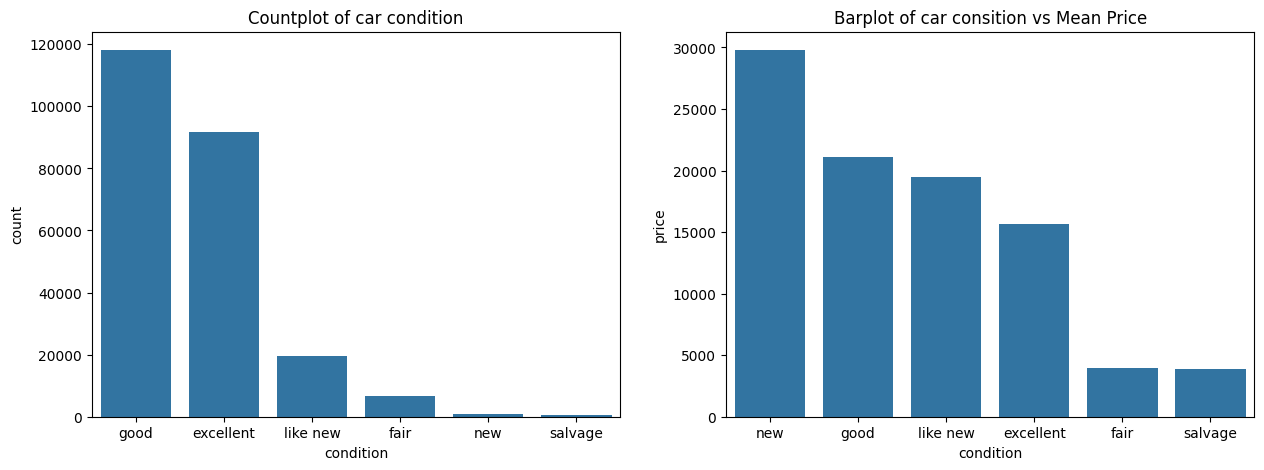

In [133]:
## condition, condition vs price
condition_df = (
    df.groupby(by="condition").agg({"price": "mean", "log_price": "mean"}).reset_index()
)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(
    data=df, x="condition", order=df["condition"].value_counts().index, ax=axes[0]
)
axes[0].set_title("Countplot of car condition")
sns.barplot(
    data=condition_df,
    x="condition",
    y="price",
    ax=axes[1],
    order=condition_df.sort_values(by="price", ascending=False)["condition"],
)
axes[1].set_title("Barplot of car consition vs Mean Price")
plt.savefig("plots/plots_condition.jpeg")
plt.show()

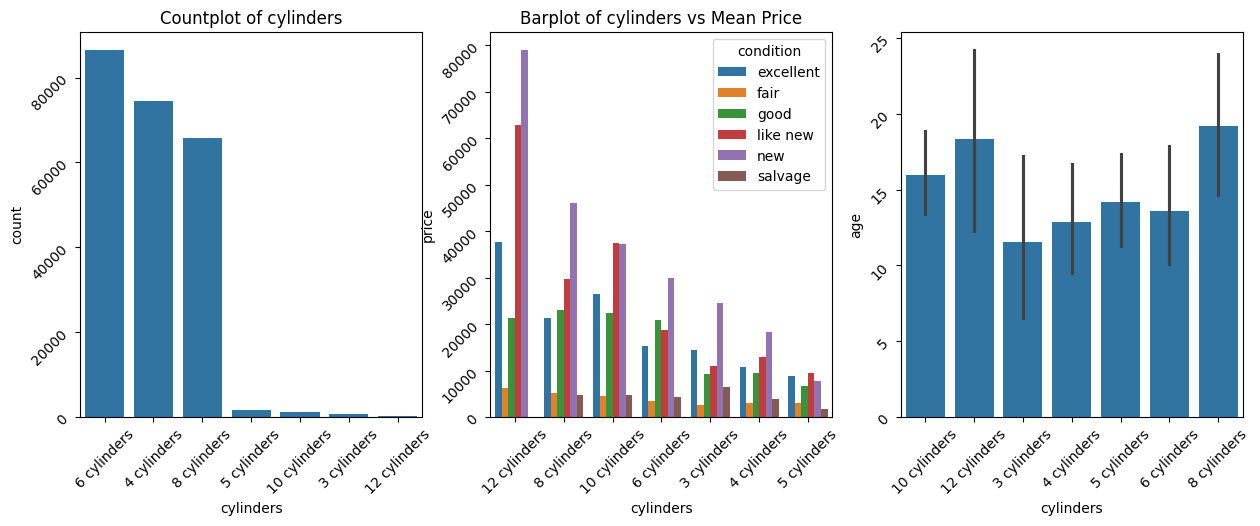

In [134]:
## cylinders, cylinders vs price
cylinders_df = (
    df.groupby(by=["cylinders", "condition"])
    .agg({"price": "mean", "log_price": "mean", "age": "mean"})
    .reset_index()
)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sns.countplot(
    data=df, x="cylinders", order=df["cylinders"].value_counts().index, ax=axes[0]
)
axes[0].set_title("Countplot of cylinders")
sns.barplot(
    data=cylinders_df,
    x="cylinders",
    y="price",
    ax=axes[1],
    order=cylinders_df.sort_values(by="price", ascending=False)["cylinders"],
    hue="condition",
)
axes[1].set_title("Barplot of cylinders vs Mean Price")
sns.barplot(data=cylinders_df, x="cylinders", y="age", ax=axes[2])
for ax in axes:
    ax.tick_params(rotation=45)
plt.savefig("plots/plots_cylinders.jpeg")
plt.show()

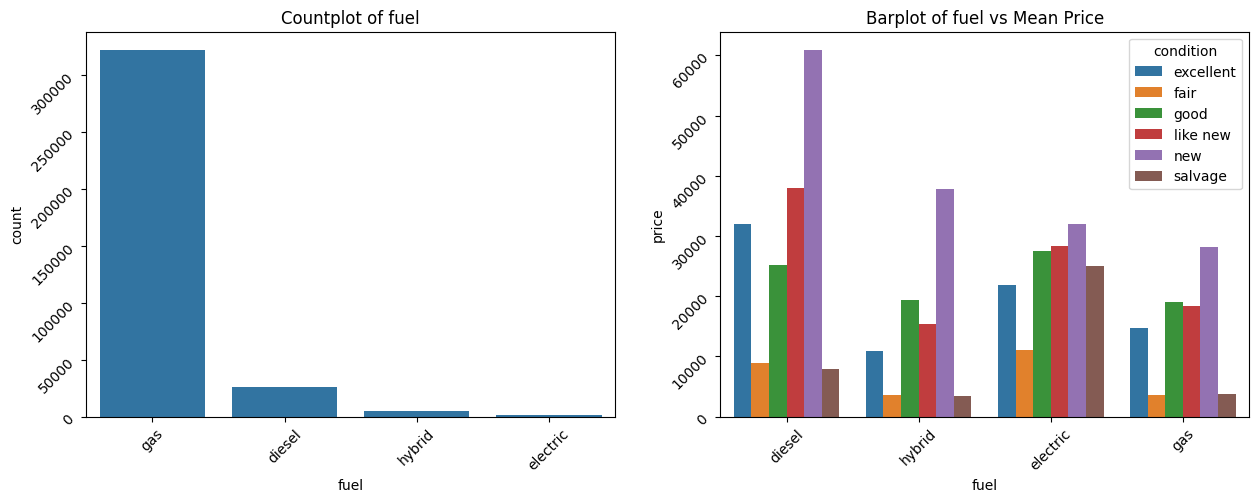

In [135]:
## fuel, fuel vs price
fuel_df = (
    df.groupby(by=["fuel", "condition"])
    .agg({"price": "mean", "log_price": "mean"})
    .reset_index()
)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="fuel", order=df["fuel"].value_counts().index, ax=axes[0])
axes[0].set_title("Countplot of fuel")
sns.barplot(
    data=fuel_df,
    x="fuel",
    y="price",
    ax=axes[1],
    order=fuel_df.sort_values(by="price", ascending=False)["fuel"],
    hue="condition",
)
axes[1].set_title("Barplot of fuel vs Mean Price")
for ax in axes:
    ax.tick_params(rotation=45)
plt.savefig("plots/plots_fuel.jpeg")
plt.show()

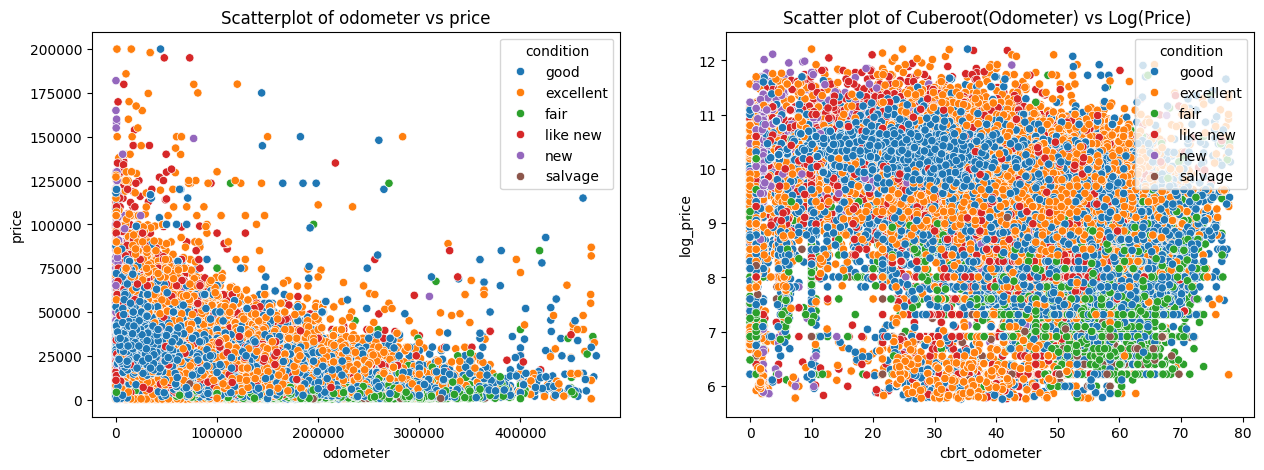

In [136]:
# odometer vs price
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=df, x="odometer", y="price", hue="condition", ax=axes[0])
axes[0].set_title("Scatterplot of odometer vs price")
sns.scatterplot(data=df, x="cbrt_odometer", y="log_price", hue="condition", ax=axes[1])
axes[1].set_title("Scatter plot of Cuberoot(Odometer) vs Log(Price) ")
plt.savefig("plots/plots_odometer.jpeg")
plt.show()

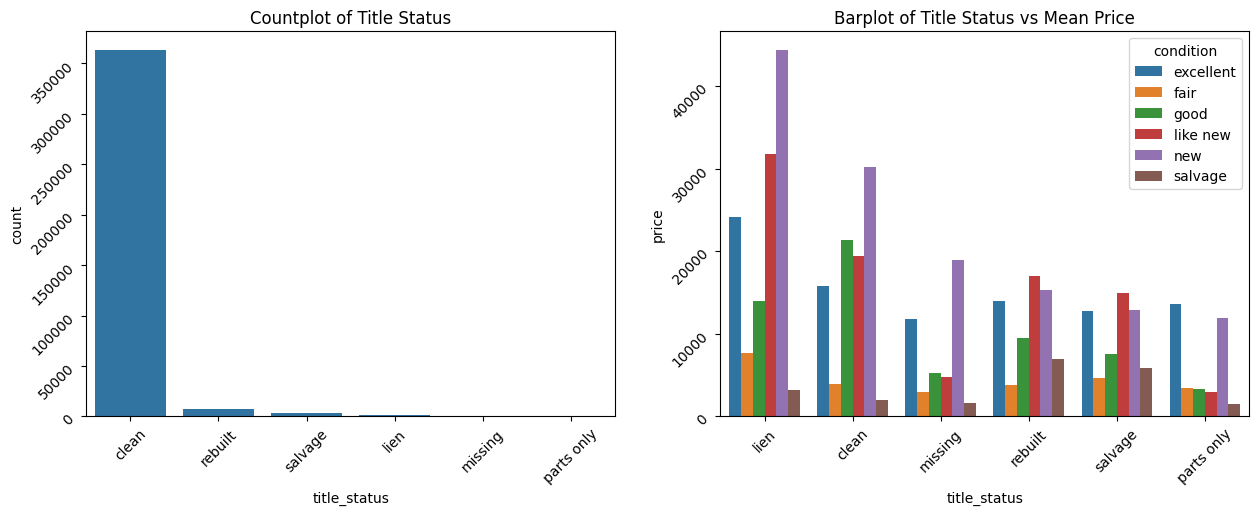

In [137]:
## Title Status, Title Status vs price
title_status_df = (
    df.groupby(by=["title_status", "condition"])
    .agg({"price": "mean", "log_price": "mean"})
    .reset_index()
)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(
    data=df, x="title_status", order=df["title_status"].value_counts().index, ax=axes[0]
)
axes[0].set_title("Countplot of Title Status")
sns.barplot(
    data=title_status_df,
    x="title_status",
    y="price",
    ax=axes[1],
    order=title_status_df.sort_values(by="price", ascending=False)["title_status"],
    hue="condition",
)
axes[1].set_title("Barplot of Title Status vs Mean Price")
for ax in axes:
    ax.tick_params(rotation=45)
plt.savefig("plots/plots_title_status.jpeg")
plt.show()

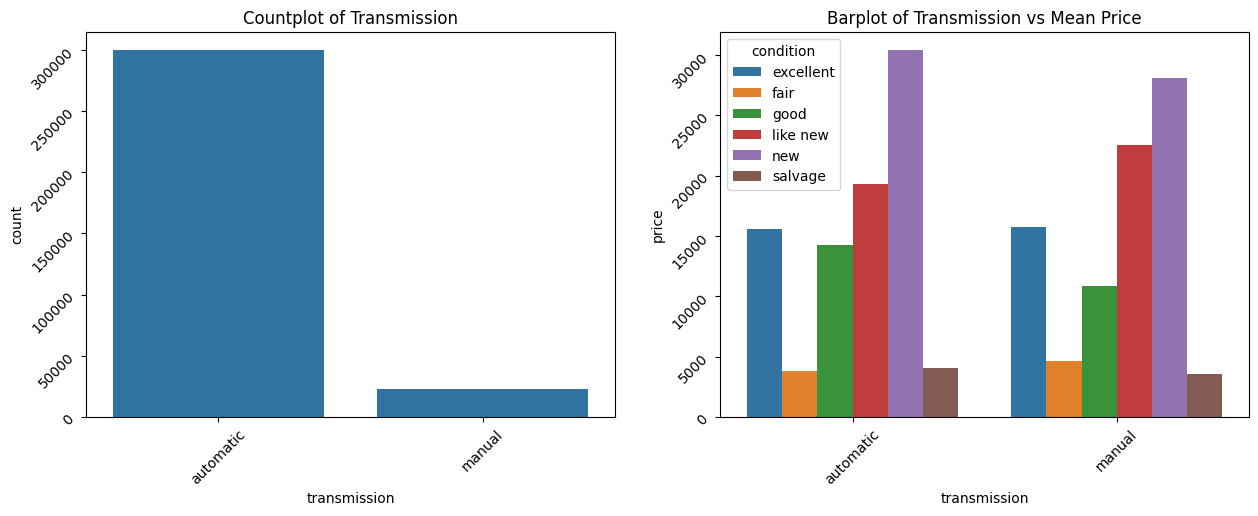

In [138]:
## Transmission, transmission vs price
transmission_df = (
    df.groupby(by=["transmission", "condition"])
    .agg({"price": "mean", "log_price": "mean"})
    .reset_index()
)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(
    data=df, x="transmission", order=df["transmission"].value_counts().index, ax=axes[0]
)
axes[0].set_title("Countplot of Transmission")
sns.barplot(
    data=transmission_df,
    x="transmission",
    y="price",
    ax=axes[1],
    order=transmission_df.sort_values(by="price", ascending=False)["transmission"],
    hue="condition",
)
axes[1].set_title("Barplot of Transmission vs Mean Price")
for ax in axes:
    ax.tick_params(rotation=45)
plt.savefig("plots/plots_transmission.jpeg")

plt.show()

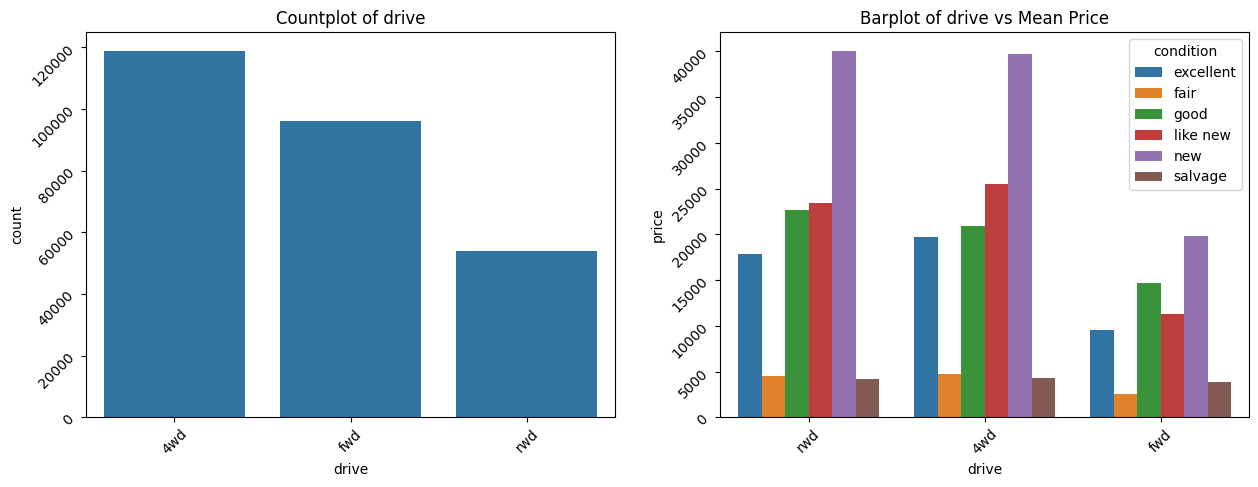

In [139]:
## drive, drive vs price
drive_df = (
    df.groupby(by=["drive", "condition"])
    .agg({"price": "mean", "log_price": "mean"})
    .reset_index()
)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="drive", order=df["drive"].value_counts().index, ax=axes[0])
axes[0].set_title("Countplot of drive")
sns.barplot(
    data=drive_df,
    x="drive",
    y="price",
    ax=axes[1],
    order=drive_df.sort_values(by="price", ascending=False)["drive"],
    hue="condition",
)
axes[1].set_title("Barplot of drive vs Mean Price")
for ax in axes:
    ax.tick_params(rotation=45)
plt.savefig("plots/plots_drive.jpeg")
plt.show()

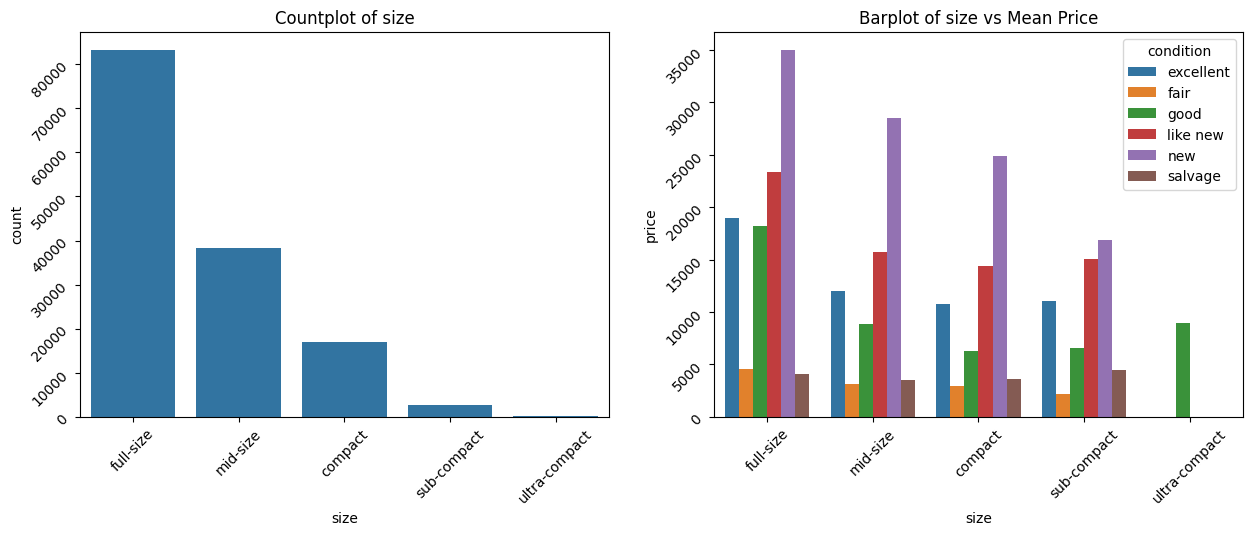

In [140]:
## size, size vs price
size_df = (
    df.groupby(by=["size", "condition"])
    .agg({"price": "mean", "log_price": "mean"})
    .reset_index()
)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="size", order=df["size"].value_counts().index, ax=axes[0])
axes[0].set_title("Countplot of size")
sns.barplot(
    data=size_df,
    x="size",
    y="price",
    ax=axes[1],
    order=size_df.sort_values(by="price", ascending=False)["size"],
    hue="condition",
)
axes[1].set_title("Barplot of size vs Mean Price")
for ax in axes:
    ax.tick_params(rotation=45)
plt.savefig("plots/plots_size.jpeg")
plt.show()

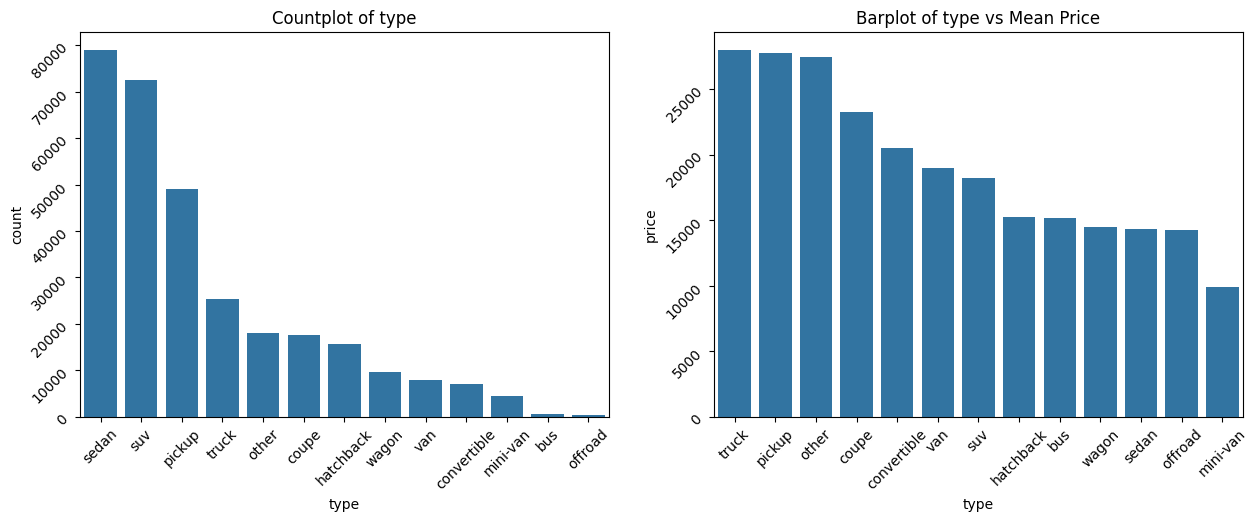

In [141]:
## type, type vs price
type_df = (
    df.groupby(by=["type"]).agg({"price": "mean", "log_price": "mean"}).reset_index()
)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="type", order=df["type"].value_counts().index, ax=axes[0])
axes[0].set_title("Countplot of type")
sns.barplot(
    data=type_df,
    x="type",
    y="price",
    ax=axes[1],
    order=type_df.sort_values(by="price", ascending=False)["type"],
)
axes[1].set_title("Barplot of type vs Mean Price")
for ax in axes:
    ax.tick_params(rotation=45)
plt.savefig("plots/plots_type.jpeg")
plt.show()

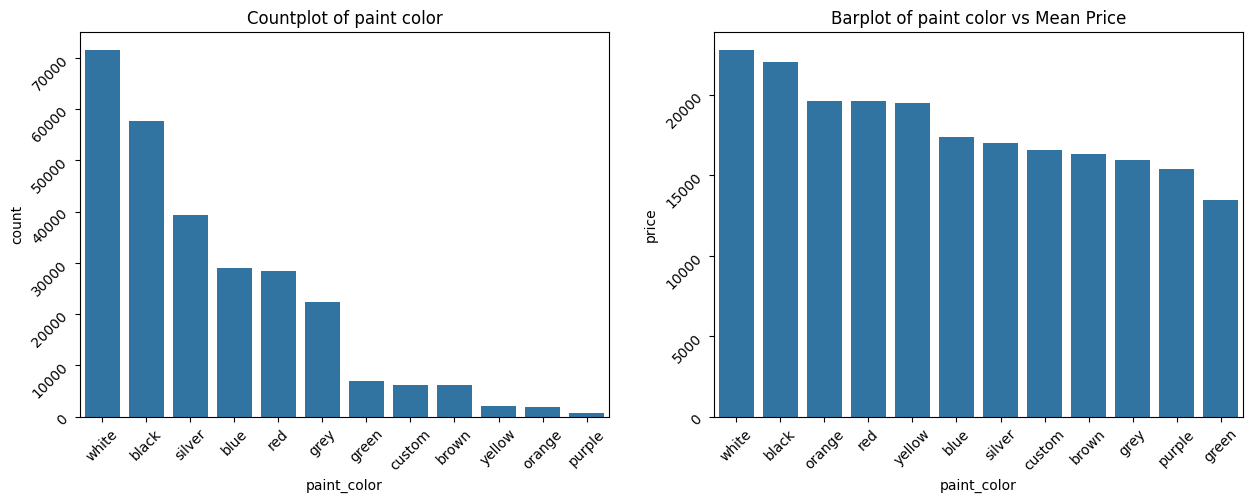

In [142]:
## Paint color, Paint color vs price
paint_color_df = (
    df.groupby(by=["paint_color"])
    .agg({"price": "mean", "log_price": "mean"})
    .reset_index()
)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(
    data=df, x="paint_color", order=df["paint_color"].value_counts().index, ax=axes[0]
)
axes[0].set_title("Countplot of paint color")
sns.barplot(
    data=paint_color_df,
    x="paint_color",
    y="price",
    ax=axes[1],
    order=paint_color_df.sort_values(by="price", ascending=False)["paint_color"],
)
axes[1].set_title("Barplot of paint color vs Mean Price")
for ax in axes:
    ax.tick_params(rotation=45)
plt.savefig("plots/plots_paint_color.jpeg")

plt.show()

### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling. Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`.


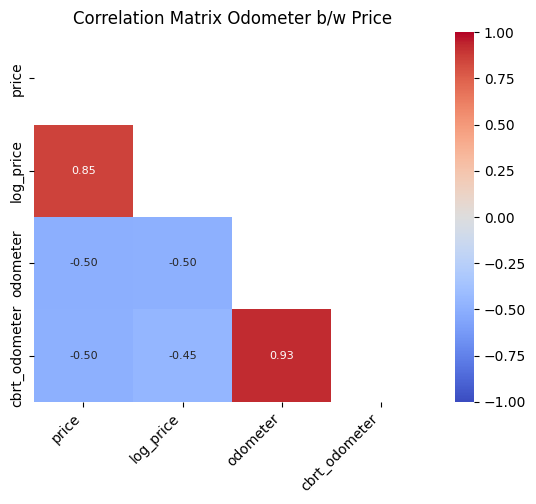

In [143]:
# odometer vs cbrt_odomotor, which is better?
odo_corr_matrix = df[["price", "log_price", "odometer", "cbrt_odometer"]].corr()

sns.heatmap(
    data=odo_corr_matrix,
    mask=np.triu(odo_corr_matrix),
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    vmax=1,
    vmin=-1,
    cmap="coolwarm",
)
plt.title("Correlation Matrix Odometer b/w Price")
plt.xticks(rotation=45, ha="right")
plt.savefig("plots/corr_matrix_odometer_price.jpeg")
plt.show()

In [144]:
## selecting variables for model building
df_select = df.drop(
    columns=[
        "drive",
        "transmission",
        "VIN",
        "model",
        "fuel",
        "title_status",
        "manufacturer",
        "year",
        "cbrt_odometer",
    ],
    axis=1,
    errors="ignore",
)
df_select.info()

<class 'pandas.core.frame.DataFrame'>
Index: 383656 entries, 27 to 426879
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   price         383656 non-null  int64  
 1   condition     237647 non-null  object 
 2   cylinders     230372 non-null  object 
 3   odometer      383656 non-null  float64
 4   size          141438 non-null  object 
 5   type          306865 non-null  object 
 6   paint_color   271792 non-null  object 
 7   log_price     383656 non-null  float64
 8   age           382547 non-null  float64
 9   brand_origin  366622 non-null  object 
 10  brand_status  366622 non-null  object 
dtypes: float64(3), int64(1), object(7)
memory usage: 35.1+ MB


In [145]:
## Test train split
X = df_select.drop(columns=["price", "log_price"])
y = df_select[["price", "log_price"]]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 76732 entries, 250829 to 232340
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   condition     47340 non-null  object 
 1   cylinders     46123 non-null  object 
 2   odometer      76732 non-null  float64
 3   size          28081 non-null  object 
 4   type          61242 non-null  object 
 5   paint_color   54287 non-null  object 
 6   age           76503 non-null  float64
 7   brand_origin  73359 non-null  object 
 8   brand_status  73359 non-null  object 
dtypes: float64(2), object(7)
memory usage: 5.9+ MB


In [146]:
## Encoding of ordinal variables: condition, size

condition_cats = [["salvage", "fair", "good", "excellent", "like new", "new"]]
size_cats = [["ultra-compact", "sub-compact", "compact", "mid-size", "full-size"]]
cylinder_cats = [
    [
        "3 cylinders",
        "4 cylinders",
        "5 cylinders",
        "6 cylinders",
        "8 cylinders",
        "10 cylinders",
        "12 cylinders",
    ]
]

## function to create ordinal pipelines for column trasformations
def make_ordinal_pipeline(cat_mapping, indi=False):
    return Pipeline(
        [
            (
                "encoder",
                OrdinalEncoder(
                    categories=cat_mapping,
                    encoded_missing_value=np.nan,
                    handle_unknown="use_encoded_value",
                    unknown_value=np.nan,
                ),
            ),
            (
                "imputer",
                SimpleImputer(
                    strategy="median", missing_values=np.nan, add_indicator=indi
                ),
            ),
            ("scaler", StandardScaler()),
        ]
    )


def discrete_pipeline(indi=False):
    return Pipeline(
        [
            ("imputer", SimpleImputer(strategy="mean", add_indicator=indi)),
            ("scaler", StandardScaler()),
        ]
    )


odometer_pipeline = Pipeline([("scaler", StandardScaler())])

In [147]:
## column transformation
base_transformer = [
    ("condition", make_ordinal_pipeline(condition_cats), ["condition"]),
    ("size", make_ordinal_pipeline(size_cats), ["size"]),
    ("cylinder", make_ordinal_pipeline(cylinder_cats), ["cylinders"]),
    (
        "paint_color",
        OneHotEncoder(
            categories=[["white", "black"]],
            handle_unknown="ignore",
            sparse_output=False,
        ),
        ["paint_color"],
    ),
    (
        "type",
        OneHotEncoder(
            categories=[["sedan", "suv", "pickup", "truck"]],
            handle_unknown="ignore",
            sparse_output=False,
        ),
        ["type"],
    ),
    (
        "brand",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop='first'),
        ["brand_status"],
    ),
    ("age", discrete_pipeline(), ["age"]),
    ("odometer", odometer_pipeline, ["odometer"]),
]

base_transformer_with_mi = [
    ("condition", make_ordinal_pipeline(condition_cats, indi=True), ["condition"]),
    ("size", make_ordinal_pipeline(size_cats, indi=True), ["size"]),
    ("cylinder", make_ordinal_pipeline(cylinder_cats, indi=True), ["cylinders"]),
    (
        "paint_color",
        OneHotEncoder(
            categories=[["white", "black"]],
            handle_unknown="ignore",
            sparse_output=False,
        ),
        ["paint_color"],
    ),
    (
        "type",
        OneHotEncoder(
            categories=[["sedan", "suv", "pickup", "truck"]],
            handle_unknown="ignore",
            sparse_output=False,
        ),
        ["type"],
    ),
    (
        "brand",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop='first'),
        ["brand_status"],
    ),
    ("age", discrete_pipeline(indi=True), ["age"]),
    ("odometer", odometer_pipeline, ["odometer"]),
]

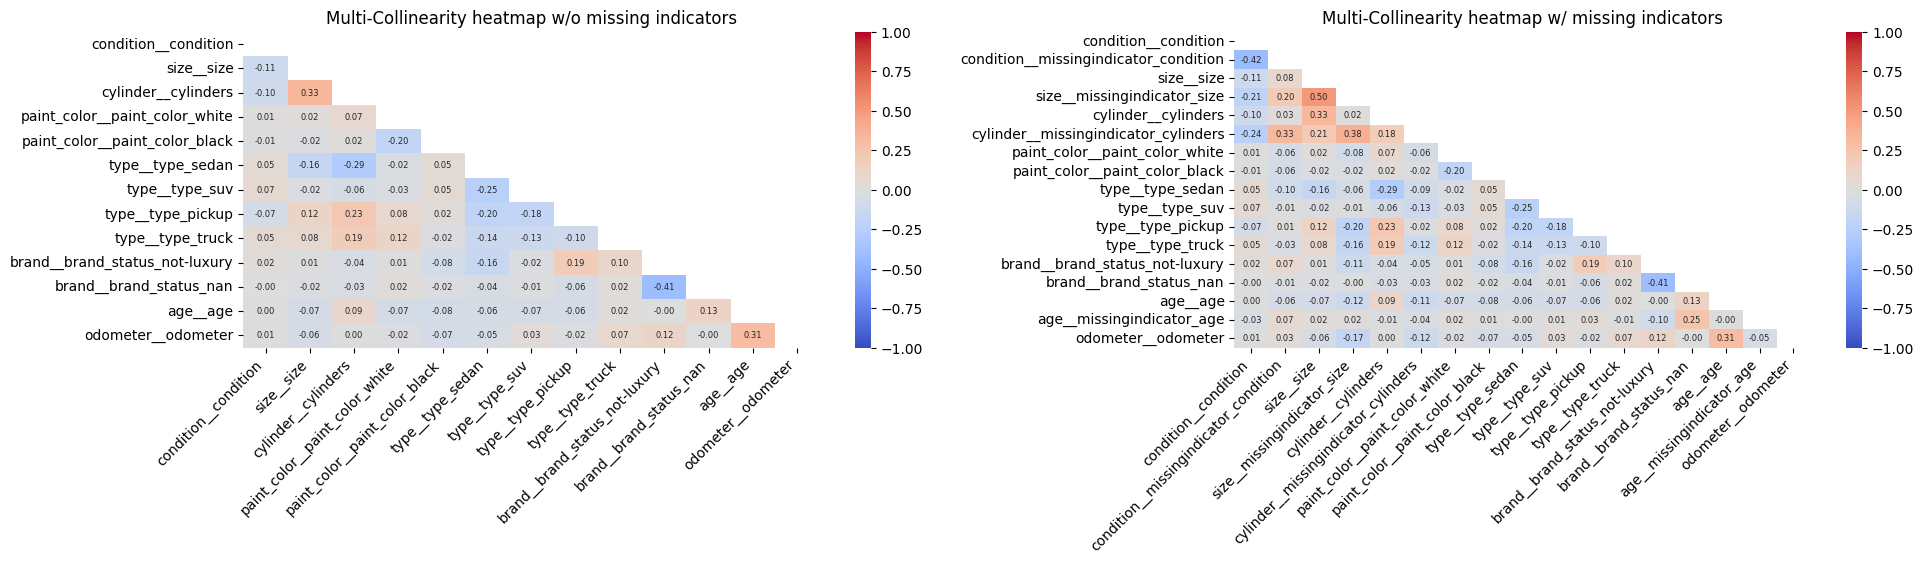

In [148]:
## Multi-Colliearity Analysis
normalised_X_train = (
    ColumnTransformer(
        base_transformer,
        remainder="drop",
    )
    .set_output(transform="pandas")
    .fit_transform(X_train)
)


normalised_X_train_with_mi = (
    ColumnTransformer(
        base_transformer_with_mi,
        remainder="drop",
    )
    .set_output(transform="pandas")
    .fit_transform(X_train)
)


fig, axes = plt.subplots(1, 2, figsize=(20, 6))

sns.heatmap(
    data=normalised_X_train.corr(),
    mask=np.triu(normalised_X_train.corr()),
    annot=True,
    fmt=".2f",
    annot_kws={"size": 6},
    vmax=1,
    vmin=-1,
    cmap="coolwarm",
    ax=axes[0],
)
axes[0].set_title("Multi-Collinearity heatmap w/o missing indicators")

sns.heatmap(
    data=normalised_X_train_with_mi.corr(),
    mask=np.triu(normalised_X_train_with_mi.corr()),
    annot=True,
    fmt=".2f",
    annot_kws={"size": 6},
    vmax=1,
    vmin=-1,
    cmap="coolwarm",
    ax=axes[1],
)
axes[1].set_title("Multi-Collinearity heatmap w/ missing indicators")
for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(pad=2.0)
plt.savefig("plots/multi_collinearity_without_brand_origin.jpeg")
plt.show()

### Modeling

With your (almost?) final dataset in hand, it is now time to build some models. Here, you should build a number of different regression models with the price as the target. In building your models, you should explore different parameters and be sure to cross-validate your findings.


In [149]:
## build model using Linear Regression. We choose linear regression as multi-colinearity is low to medium
model = LinearRegression(fit_intercept=True)
model.fit(normalised_X_train, y_train["price"])
model_with_mi = LinearRegression(fit_intercept=True).fit(
    normalised_X_train_with_mi, y_train["price"]
)
model_of_log_price = LinearRegression(fit_intercept=True).fit(
    normalised_X_train, y_train["log_price"]
)
model_of_log_price_with_mi = LinearRegression(fit_intercept=True).fit(
    normalised_X_train_with_mi, y_train["log_price"]
)

print(
    "rsme test of model(train): ",
    root_mean_squared_error(model.predict(normalised_X_train), y_train["price"]),
)
print(
    "rsme test of model w/ mi(train): ",
    root_mean_squared_error(
        model_with_mi.predict(normalised_X_train_with_mi), y_train["price"]
    ),
)
print(
    "rsme test of model of log price(train): ",
    root_mean_squared_error(
        np.e ** model_of_log_price.predict(normalised_X_train), y_train["price"]
    ),
)
print(
    "rsme test of model w/ mi of log price(train): ",
    root_mean_squared_error(
        np.e ** model_of_log_price_with_mi.predict(normalised_X_train_with_mi),
        y_train["price"],
    ),
)

rsme test of model(train):  11213.843756668546
rsme test of model w/ mi(train):  11143.658159573657
rsme test of model of log price(train):  11374.125166614927
rsme test of model w/ mi of log price(train):  11257.43487779968


In [150]:
## model coefficients
coef_df = pd.DataFrame({'coef_values': model.coef_, 'coef_name':model.feature_names_in_})
coef_df['abs_coef_value'] = abs(coef_df['coef_values'])
coef_df.sort_values(by='abs_coef_value', ascending=False)

,coef_values,coef_name,abs_coef_value
8,9767.396079,type__type_truck,9767.396079
7,7333.337404,type__type_pickup,7333.337404
12,-6429.941790,odometer__odometer,6429.941790
5,-3702.270466,type__type_sedan,3702.270466
11,-3328.510590,age__age,3328.510590
9,-3306.707425,brand__brand_status_not-luxury,3306.707425
2,2725.272794,cylinder__cylinders,2725.272794
10,2377.185341,brand__brand_status_nan,2377.185341
3,1838.302483,paint_color__paint_color_white,1838.302483
4,1543.991071,paint_color__paint_color_black,1543.991071


### Evaluation

With some modeling accomplished, we aim to reflect on what we identify as a high-quality model and what we are able to learn from this. We should review our business objective and explore how well we can provide meaningful insight into drivers of used car prices. Your goal now is to distill your findings and determine whether the earlier phases need revisitation and adjustment or if you have information of value to bring back to your client.


In [151]:
## K-fold cross validatio to calculate training RMSE and Validation RMSE
def evaluate_transformer_combinations(
    base_transformer, X, y, model, cv=5, scoring="neg_root_mean_squared_error"
):
    results = []
    for r in range(1, len(base_transformer) + 1):
        for combo in combinations(base_transformer, r):
            ct = ColumnTransformer(transformers=list(combo), remainder="drop")
            pipe = Pipeline([("prep", ct), ("model", model)])

            cv_result = cross_validate(
                estimator=pipe,
                X=X,
                y=y,
                cv=cv,
                scoring=scoring,
                return_train_score=True,
            )

            train_scores = -cv_result["train_score"]
            val_scores = -cv_result["test_score"]

            ct.fit(X, y)
            results.append(
                {
                    "feature_count": ct.get_feature_names_out().size,
                    "features": tuple(c[0] for c in combo),
                    "train_rmse": train_scores.mean(),  ##reverse the sign of RMSE generated by sklearn
                    "train_std": train_scores.std(),
                    "val_rmse": val_scores.mean(),
                    "val_std": val_scores.std(),
                }
            )
    return pd.DataFrame(results)


model_complexity = evaluate_transformer_combinations(
    base_transformer,
    X_train,
    y_train["price"],
    model=LinearRegression(fit_intercept=True),
)

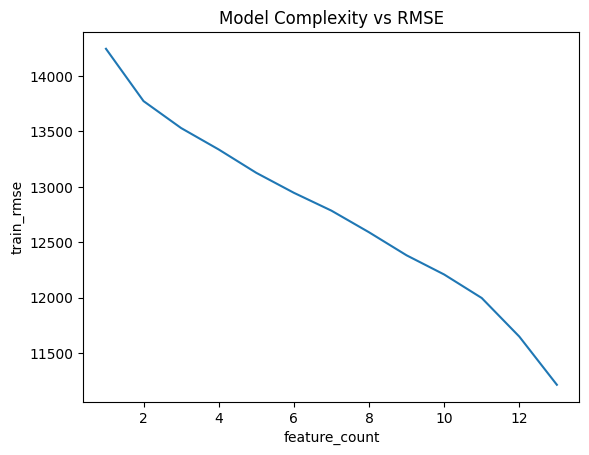

In [152]:
## model complexity vs RMSE analysis
mc_data = (
    model_complexity.drop(columns=["features"], errors="ignore")
    .groupby(by="feature_count")
    .mean()
)
sns.lineplot(data=mc_data, x="feature_count", y="train_rmse", errorbar=None)
plt.title("Model Complexity vs RMSE")
plt.savefig("plots/model_complexity.jpeg")

In [153]:
## RMSE test
print(
    "rmse of price (test): ",
    root_mean_squared_error(
        model.predict(
            ColumnTransformer(
                base_transformer,
                remainder="drop",
            )
            .set_output(transform="pandas")
            .fit_transform(X_test)
        ),
        y_test["price"],
    ),
)

rmse of price (test):  11235.173333741797


### Deployment

Now that we've settled on our models and findings, it is time to deliver the information to the client. You should organize your work as a basic report that details your primary findings. Keep in mind that your audience is a group of used car dealers interested in fine-tuning their inventory.


In [154]:
## permutation matrix to evaluate which independent feature impacts the most
model_complexity.sort_values(by='val_rmse', ascending=False)
model_complexity ['delta'] = model_complexity.apply(lambda x: abs(x['val_rmse'] - model_complexity.loc[model_complexity['feature_count'] == x['feature_count']-1,'val_rmse'].min()), axis=1)
model_complexity.sort_values(by=['feature_count','delta'], ascending= False).groupby(by='feature_count')[['features', 'delta']].agg({'features':'first', 'delta':'max'}).sort_values(by='feature_count', ascending=False)

,features,delta
feature_count,,
13,"(condition, size, cylinder, paint_color, type,...",1.049220
12,"(condition, size, cylinder, paint_color, type,...",1510.836562
11,"(condition, size, cylinder, paint_color, type,...",2485.779364
10,"(condition, size, paint_color, type, brand)",2592.956877
9,"(condition, paint_color, type, brand)",2575.841480
8,"(condition, size, paint_color, type)",2701.823863
7,"(condition, paint_color, type)",2463.091809
6,"(condition, size, paint_color, brand)",2724.282026
5,"(condition, paint_color, brand)",2891.840905
